In [10]:
import numpy as np
import matplotlib.pyplot as plt
import scipy 
from scipy.stats import norm

In [11]:
stats.norm.rvs()

NameError: name 'stats' is not defined

In [12]:
import pandas as pd

<AxesSubplot: ylabel='Density'>

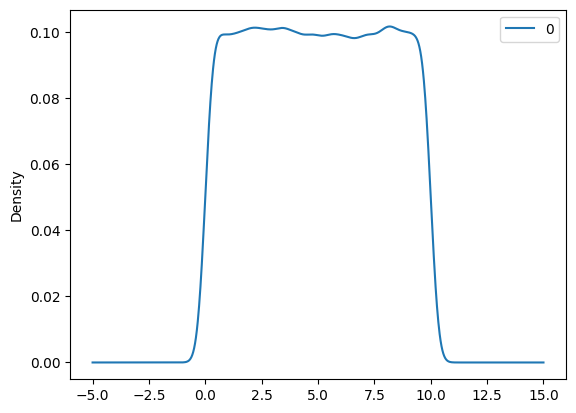

In [13]:
import scipy.stats as stats

uniform_data = stats.uniform.rvs(size=100000,
                 loc=0, #from 0
                 scale=10 #to 10
                 )

pd.DataFrame(uniform_data).plot(kind='density')

<AxesSubplot: ylabel='Density'>

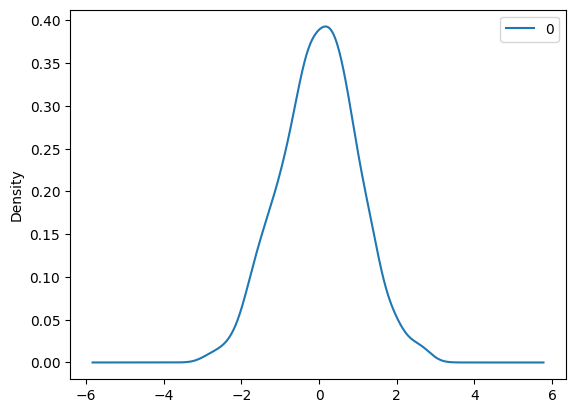

In [14]:
normal_data = stats.norm.rvs(size=1000,
                            loc=0,
                            scale = 1
                            )
pd.DataFrame(normal_data).plot(kind='density')

<AxesSubplot: ylabel='Frequency'>

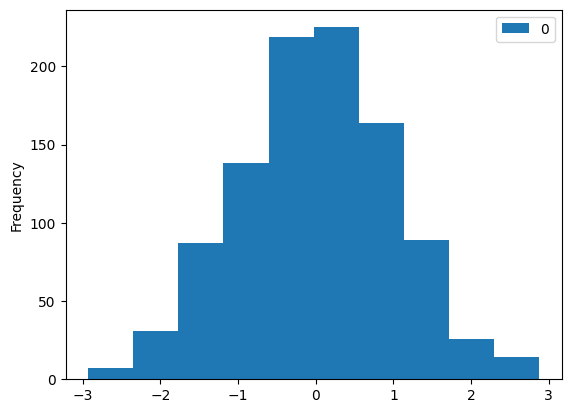

In [15]:
pd.DataFrame(normal_data).plot(kind='hist')

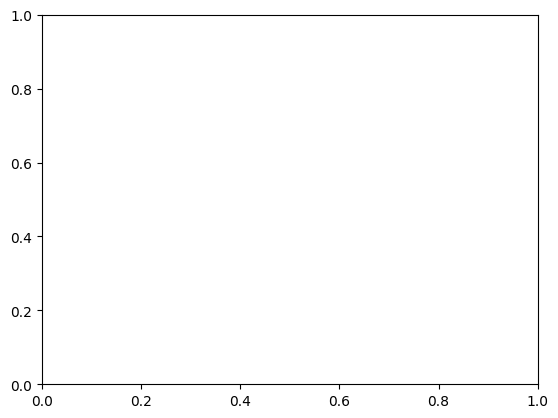

In [16]:
from scipy.stats import f

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1)


In [17]:
dfn, dfd = 29, 18

mean, var, skew, kurt = f.stats(dfn, dfd, moments='mvsk')

In [18]:


x = np.linspace(f.ppf(0.01, dfn, dfd),

                f.ppf(0.99, dfn, dfd), 100)

ax.plot(x, f.pdf(x, dfn, dfd),

       'r-', lw=5, alpha=0.6, label='f pdf')

In [19]:
rv = f(dfn, dfd)

ax.plot(x, rv.pdf(x), 'k-', lw=2, label='frozen pdf')

In [20]:
vals = f.ppf([0.001, 0.5, 0.999], dfn, dfd)

np.allclose([0.001, 0.5, 0.999], f.cdf(vals, dfn, dfd))
True


True

In [26]:
r = stats.f.rvs(dfn, dfd, size=1000)

In [27]:
ax.hist(r, density=True, histtype='stepfilled', alpha=0.2)

ax.legend(loc='best', frameon=False)

plt.show()

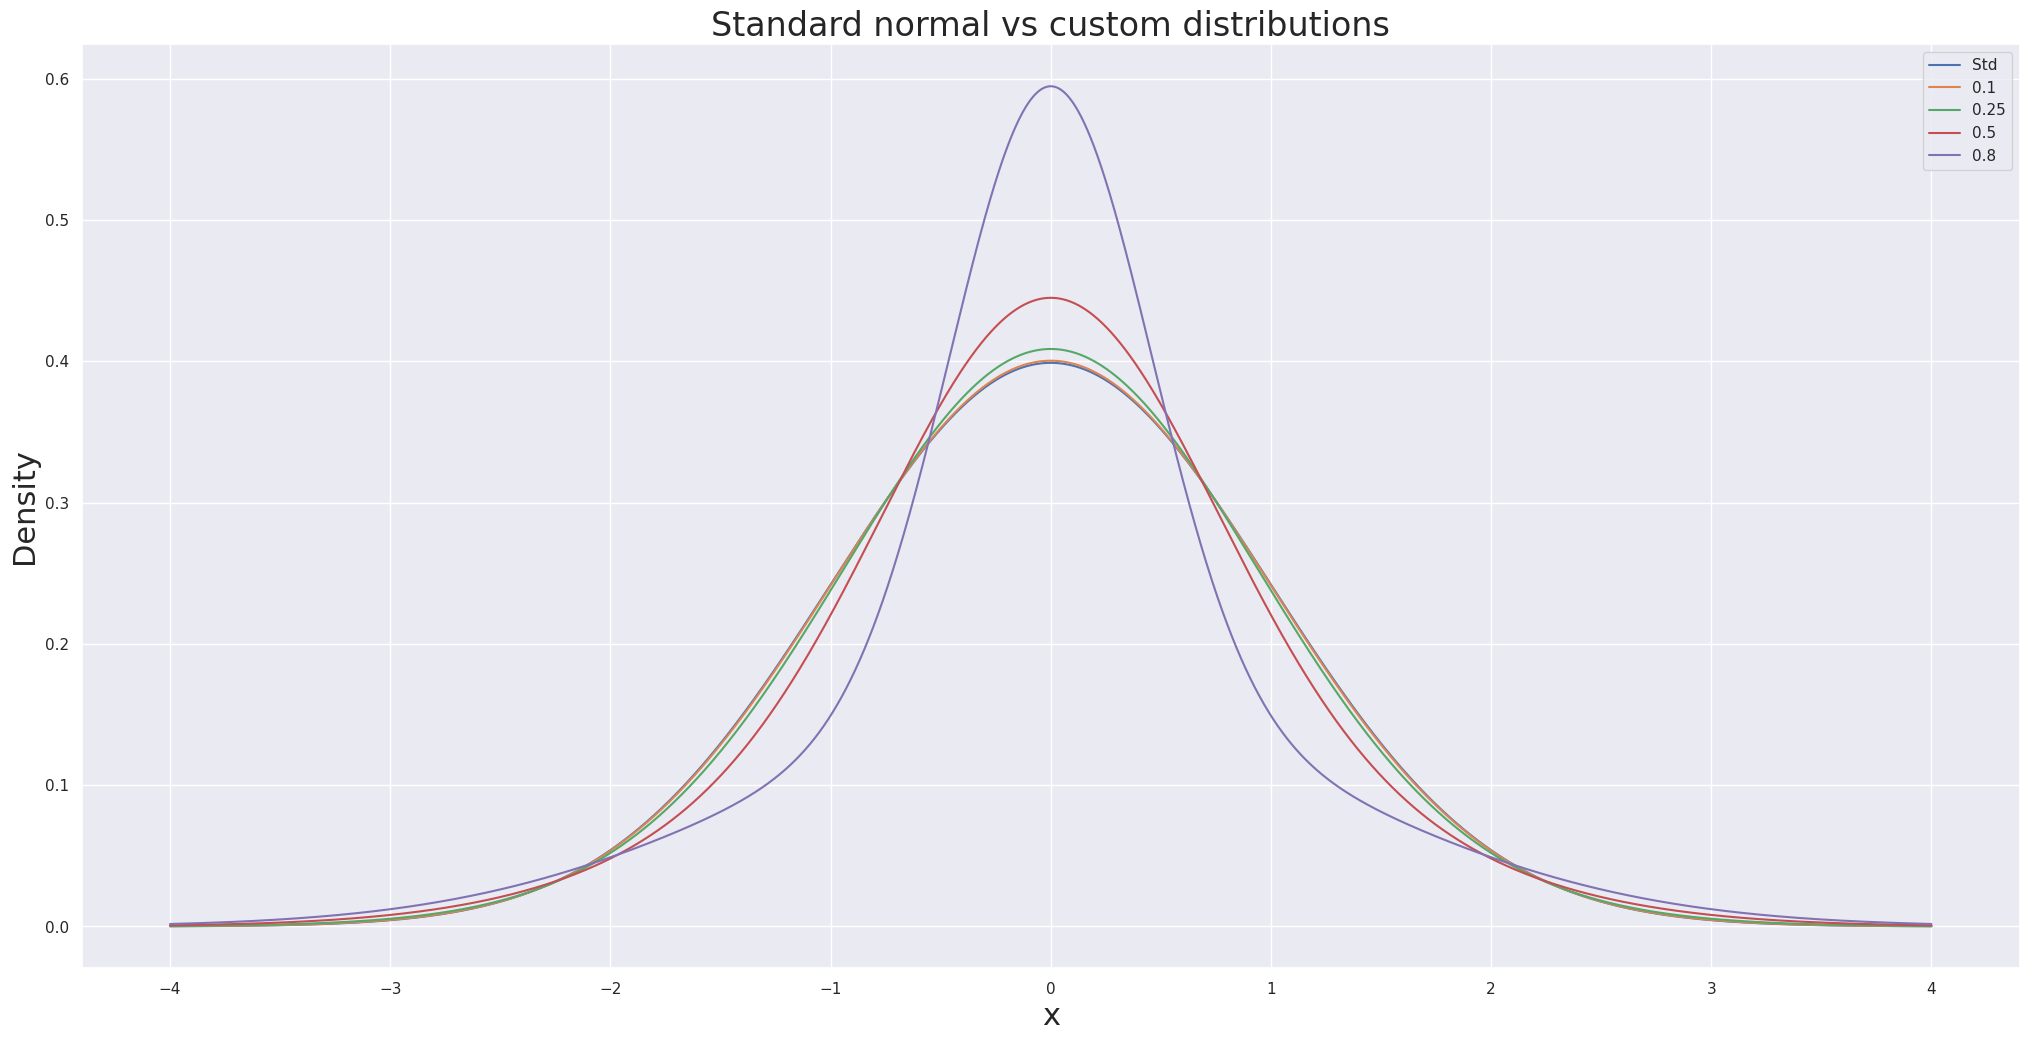

In [32]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import warnings

from scipy.integrate import simps
from scipy.interpolate import interp1d

# some config
%config Completer.use_jedi = False
warnings.filterwarnings('ignore')
sns.set() 

# this is the 1d domain over which our pdf exists
xs = np.linspace(-4.0, 4.0, 10000)

# define normal pdf
def norm_p(x, mu=0, sigma=1):
    return (1 / (sigma * (2 * np.pi)**0.5)) * np.exp(-0.5 * ((x - mu)**2 / sigma**2))

# define our custom pdf as the average of normals
def p(x, mu=0, sigma=1, sigma_dev=0):
    low = norm_p(x, mu, sigma * (1 - sigma_dev)**0.5)
    high = norm_p(x, mu, sigma * (1 + sigma_dev)**0.5)
    return 0.5 * (low + high)

# define our params
mu = 0
sigma = 1
devs = [0.1, 0.25, 0.5, 0.8]
pdfs = {'Std': [norm_p(x) for x in xs]}

# compute pdfs of our custom dist with various varince deviations
for d in devs:
    pdf = [p(x, sigma_dev=d) for x in xs]
    pdfs[d] = pdf

# plot them
fig, ax = plt.subplots(ncols=1, figsize=(25,12))
for label, pdf in pdfs.items():
    ax.plot(xs, pdf, label=label)

    # label them
ax.legend()
ax.set_title('Standard normal vs custom distributions', fontsize=24)
ax.set_xlabel('x', fontsize=22)
ax.set_ylabel('Density', fontsize=22);
plt.savefig("myplot.png")

In [31]:
import random
x = random.sample([1, -1], True,[0.4, 0.6])

TypeError: Random.sample() takes 3 positional arguments but 4 were given